# 04 · Analysis

Everything in this notebook is computed from the fold scores saved by `03_experiments` (`results/runs/`). Only two parts train anything again: the RBF kernels of the concentration analysis (section 4) and the shuffled-label test (section 5), both on the same folds as the runs. The test rows are not used.

| Section | Question |
|---|---|
| 1 | Do the new runs agree with the earlier ones where nothing changed? (one-time check) |
| 2 | Results: clean performance, best bandwidth (RQ1), which damage hurts most (RQ2), quantum vs SVM-RBF (RQ3) |
| 3 | Statistics: which differences are real? |
| 4 | Concentration: why does damage hurt the quantum kernel? |
| 5 | The small-c puzzle: are small-bandwidth scores genuine, and what does the kernel resemble? |

Final tables and figures are saved to `results/analysis/`.

## 0 · Setup

In [1]:
import re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import spearmanr
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.metrics.pairwise import euclidean_distances

from paths import RESULTS
from quantum_kernel import load_ready, get_states, kernel_from_states, off_diagonal_stats
from classical_models import SEEDS
from corruption import LEVELS, corrupt_training, corruption_seed, noise_columns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

DATASETS = ["german_credit", "concrete", "water_potability", "steel_faults",
            "phoneme", "magic_telescope", "bank_marketing", "electricity"]
SHORT = {"german_credit": "German", "concrete": "Concrete", "water_potability": "Water", "steel_faults": "Steel",
         "phoneme": "Phoneme", "magic_telescope": "MAGIC", "bank_marketing": "Bank", "electricity": "Electricity"}
MODELS = {"quantum (c,C tuned)": "Quantum", "svm_rbf": "SVM-RBF", "random_forest": "RF", "logistic_regression": "LR"}
Q, RBF = "quantum (c,C tuned)", "svm_rbf"
BANDWIDTHS = [0.01, 0.025, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0]
C_GRID = [0.1, 1, 10]
RUNS, OUT = RESULTS / "runs", RESULTS / "analysis"
OUT.mkdir(parents=True, exist_ok=True)


def setting(kind, level):
    if kind == "clean":
        return "clean"
    return f"noise {level:g}" if kind == "noise" else f"{kind} {level:.0%}"


ORDER = ["clean"] + [setting(k, l) for k, ls in LEVELS.items() for l in ls]
STRONGEST = {k: setting(k, ls[-1]) for k, ls in LEVELS.items()}

F = pd.concat([pd.read_csv(RUNS / f"{name}_folds.csv") for name in DATASETS], ignore_index=True)
F["level"] = F.level.round(4)
F["setting"] = [setting(k, l) for k, l in zip(F.kind, F.level)]
MAIN = F[F.model.isin(MODELS)]
FIXED = F[F.model == "quantum (c fixed)"]
print(f"{len(F):,} rows from {F.dataset.nunique()} datasets, {F.groupby(['dataset', 'setting', 'seed', 'fold']).ngroups:,} folds")

24,000 rows from 8 datasets, 2,000 folds


## 1 · Agreement with the earlier runs (one-time check)

The new run repeated everything with one change: measurement noise now touches measured columns only. So every setting **except noise on datasets with code columns** must give the same scores as before. Small differences can come from rounding in the near-singular kernels at very small c (and German, Steel and Water were first run with the slower PennyLane encoder).

This cell needs the old result folders; once they are deleted it simply reports that it was skipped.

In [2]:
OLD = {n: RESULTS / "enh_E5" / "runs" / f"day18_{n}_folds.csv"
       for n in ["concrete", "phoneme", "electricity", "magic_telescope", "bank_marketing"]}
OLD |= {n: RESULTS / "day18" / f"day18_{n}_folds.csv" for n in ["german_credit", "steel_faults", "water_potability"]}

if not all(p.exists() for p in OLD.values()):
    print("Old result files not found - check skipped.")
else:
    rows = {}
    for name in DATASETS:
        old = pd.read_csv(OLD[name]); old["level"] = old.level.round(4)
        both = MAIN[MAIN.dataset == name].merge(old[old.model.isin(MODELS)], on=["kind", "level", "seed", "fold", "model"],
                                                suffixes=("", "_old"))
        diff = (both.auc - both.auc_old).abs()
        same_rule = noise_columns(name).all()
        unchanged = both if same_rule else both[both.kind != "noise"]
        d_un = (unchanged.auc - unchanged.auc_old).abs()
        rows[SHORT[name]] = {
            "noise rule changed": "no" if same_rule else "yes",
            "unchanged settings: folds identical": f"{(d_un < 1e-9).mean():.1%}",
            "largest difference": round(d_un.max(), 4),
            "mean AUC old → new (all unchanged)": f"{unchanged.auc_old.mean():.3f} → {unchanged.auc.mean():.3f}",
            "noise 0.3, Quantum old → new": "same rule" if same_rule else
                f"{both[(both.setting == 'noise 0.3') & (both.model == Q)].auc_old.mean():.3f} → "
                f"{both[(both.setting == 'noise 0.3') & (both.model == Q)].auc.mean():.3f}"}
    display(pd.DataFrame(rows).T)

,noise rule changed,unchanged settings: folds identical,largest difference,mean AUC old → new (all unchanged),"noise 0.3, Quantum old → new"
German,yes,99.4%,0.0588,0.720 → 0.720,0.707 → 0.724
Concrete,yes,100.0%,0.0,0.915 → 0.915,0.910 → 0.914
Water,no,99.9%,0.0013,0.535 → 0.535,same rule
Steel,yes,99.7%,0.0014,0.746 → 0.746,0.754 → 0.754
Phoneme,no,100.0%,0.0,0.858 → 0.858,same rule
MAGIC,no,100.0%,0.0,0.848 → 0.848,same rule
Bank,yes,100.0%,0.0,0.653 → 0.653,0.627 → 0.683
Electricity,yes,100.0%,0.0,0.789 → 0.789,0.783 → 0.781


## 2 · Results

### 2.1 Clean data

ROC-AUC on the clean checking folds (mean ± SD over 25 folds). The quantum model is the one with c and C tuned in the inner loop.

In [3]:
def mean_sd(s):
    return f"{s.mean():.3f} ± {s.std(ddof=0):.3f}"


clean = MAIN[MAIN.setting == "clean"]
rows = {}
for name in DATASETS:
    g = clean[clean.dataset == name]
    r = {"qubits": load_ready(name)[0].shape[1]}
    r |= {MODELS[m]: mean_sd(g[g.model == m].auc) for m in MODELS}
    q, b = g[g.model == Q].set_index(["seed", "fold"]).auc, g[g.model == RBF].set_index(["seed", "fold"]).auc
    r["Quantum − RBF"] = f"{(q - b).mean():+.3f}"
    r["folds Quantum wins"] = f"{((q - b) > 0).sum()}/25"
    best = FIXED[(FIXED.dataset == name) & (FIXED.setting == "clean")].groupby("c").auc.mean()
    r["best fixed c"] = best.idxmax()
    rows[SHORT[name]] = r
T_clean = pd.DataFrame(rows).T
T_clean.to_csv(OUT / "table_clean.csv")
T_clean

,qubits,Quantum,SVM-RBF,RF,LR,Quantum − RBF,folds Quantum wins,best fixed c
German,14,0.719 ± 0.071,0.732 ± 0.066,0.740 ± 0.060,0.736 ± 0.060,-0.013,9/25,0.01
Concrete,8,0.925 ± 0.036,0.930 ± 0.037,0.925 ± 0.033,0.931 ± 0.034,-0.005,8/25,0.05
Water,9,0.535 ± 0.081,0.627 ± 0.089,0.603 ± 0.069,0.435 ± 0.064,-0.092,3/25,0.25
Steel,14,0.747 ± 0.063,0.774 ± 0.052,0.796 ± 0.050,0.753 ± 0.058,-0.027,7/25,0.1
Phoneme,5,0.849 ± 0.053,0.879 ± 0.047,0.899 ± 0.039,0.840 ± 0.049,-0.029,3/25,0.1
MAGIC,8,0.849 ± 0.055,0.878 ± 0.049,0.889 ± 0.047,0.821 ± 0.063,-0.029,4/25,0.1
Bank,14,0.667 ± 0.104,0.649 ± 0.094,0.768 ± 0.091,0.632 ± 0.111,+0.018,14/25,1.0
Electricity,6,0.777 ± 0.043,0.797 ± 0.045,0.811 ± 0.048,0.805 ± 0.055,-0.021,5/25,0.05


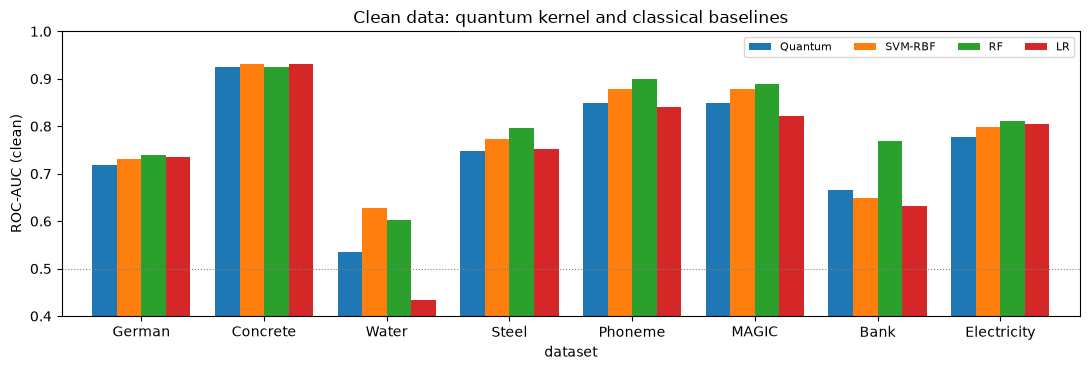

In [4]:
m = clean.groupby(["dataset", "model"]).auc.mean().unstack()[list(MODELS)].rename(columns=MODELS).loc[DATASETS]
ax = m.rename(index=SHORT).plot.bar(figsize=(11, 3.8), width=0.8, rot=0, ylim=(0.4, 1.0))
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
ax.set_ylabel("ROC-AUC (clean)"); ax.set_title("Clean data: quantum kernel and classical baselines")
ax.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.savefig(OUT / "fig_clean_auc.png", dpi=150); plt.show()

### 2.2 RQ1 · Does damage move the best bandwidth?

Best fixed c = the bandwidth with the highest mean AUC at each setting (a description, not a test).

In [5]:
best_c = FIXED.groupby(["dataset", "setting", "c"]).auc.mean().reset_index()
best_c = best_c.loc[best_c.groupby(["dataset", "setting"]).auc.idxmax()].pivot(index="dataset", columns="setting", values="c")
best_c = best_c.loc[DATASETS, ORDER].rename(index=SHORT)
best_c.to_csv(OUT / "table_rq1_best_c.csv")
best_c.style.format("{:g}").apply(lambda r: ["background-color: #fde2c8" if v != r["clean"] else "" for v in r], axis=1)

setting,clean,missing 10%,missing 20%,missing 30%,noise 0.05,noise 0.15,noise 0.3,labels 5%,labels 10%,labels 15%
dataset,,,,,,,,,,
German,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01
Concrete,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.05
Water,0.25,0.25,0.25,0.25,0.25,0.25,0.25,0.25,0.1,0.1
Steel,0.1,0.1,0.1,0.025,0.1,0.1,0.1,0.1,0.1,0.1
Phoneme,0.1,0.1,0.1,0.01,0.1,0.1,0.25,0.1,0.05,0.05
MAGIC,0.1,0.1,0.1,0.1,0.1,0.1,0.05,0.1,0.05,0.05
Bank,1,1,1,1,1,1,1,1,1,0.025
Electricity,0.05,0.05,0.05,0.025,0.05,0.05,0.025,0.05,0.05,0.025


### 2.3 RQ2 · Which damage hurts most?

Paired AUC change from clean at the strongest level of each damage (same folds). More negative = more damage.

In [6]:
W = {name: MAIN[MAIN.dataset == name].pivot_table(index=["setting", "seed", "fold"], columns="model", values="auc")
     for name in DATASETS}
rows = {}
for name, w in W.items():
    r = {}
    for kind, s in STRONGEST.items():
        for m in [Q, RBF]:
            r[(kind, MODELS[m])] = (w.loc[s, m] - w.loc["clean", m]).mean()
    rows[SHORT[name]] = r
T_rq2 = pd.DataFrame(rows).T
T_rq2.columns = pd.MultiIndex.from_tuples(T_rq2.columns)
T_rq2.to_csv(OUT / "table_rq2_drops.csv")
T_rq2.style.format("{:+.3f}").background_gradient(cmap="Reds_r", axis=None)

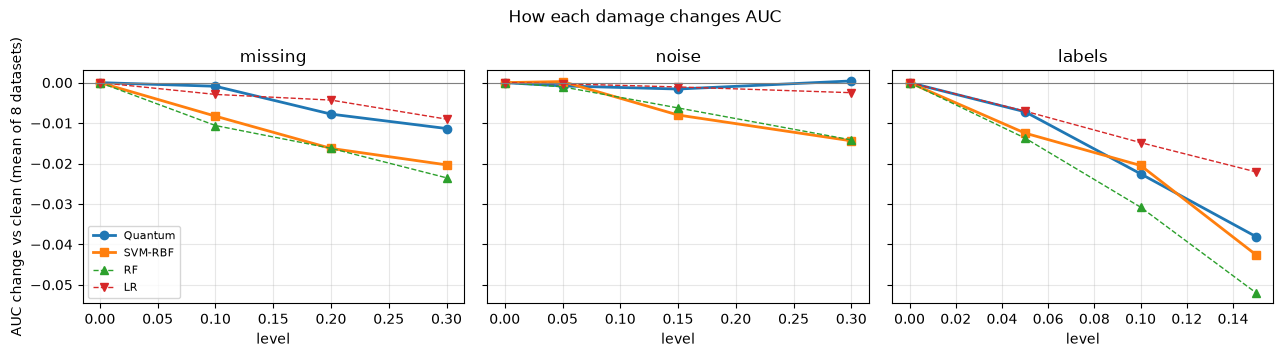

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (kind, levels) in zip(axes, LEVELS.items()):
    xs = [0.0] + list(levels)
    for m, style in zip(MODELS, ["o-", "s-", "^--", "v--"]):
        ys = [np.mean([(w.loc[setting(kind, l) if l else "clean", m] - w.loc["clean", m]).mean() for w in W.values()])
              for l in xs]
        ax.plot(xs, ys, style, label=MODELS[m], lw=2 if m in (Q, RBF) else 1)
    ax.axhline(0, color="grey", lw=0.8); ax.set_title(kind); ax.set_xlabel("level"); ax.grid(alpha=0.3)
axes[0].set_ylabel("AUC change vs clean (mean of 8 datasets)"); axes[0].legend(fontsize=8)
fig.suptitle("How each damage changes AUC"); plt.tight_layout(); plt.savefig(OUT / "fig_damage_curves.png", dpi=150); plt.show()

### 2.4 RQ3 · Quantum minus SVM-RBF at every setting

Paired difference in AUC (negative = quantum behind). Whether these gaps are real is tested in section 3.

In [8]:
T_rq3 = pd.DataFrame({SHORT[n]: (w[Q] - w[RBF]).groupby(level="setting").mean() for n, w in W.items()}).loc[ORDER]
T_rq3.to_csv(OUT / "table_rq3_q_minus_rbf.csv")
T_rq3.style.format("{:+.3f}").background_gradient(cmap="RdBu", vmin=-0.1, vmax=0.1)

,German,Concrete,Water,Steel,Phoneme,MAGIC,Bank,Electricity
setting,,,,,,,,
clean,-0.013,-0.005,-0.092,-0.027,-0.029,-0.029,+0.018,-0.021
missing 10%,-0.003,-0.004,-0.101,-0.019,-0.018,-0.030,+0.057,-0.021
missing 20%,-0.010,+0.001,-0.068,-0.029,-0.023,-0.026,+0.039,-0.013
missing 30%,-0.002,-0.009,-0.061,-0.030,-0.011,-0.029,+0.044,-0.027
noise 0.05,-0.011,-0.008,-0.097,-0.026,-0.039,-0.033,+0.021,-0.014
noise 0.15,-0.013,-0.004,-0.082,-0.018,-0.027,-0.025,+0.034,-0.011
noise 0.3,-0.002,-0.011,-0.050,-0.018,-0.023,-0.015,+0.051,-0.010
labels 5%,-0.006,-0.005,-0.057,-0.009,-0.024,-0.032,-0.018,-0.005
labels 10%,-0.037,-0.019,-0.095,-0.015,-0.021,-0.032,+0.026,-0.022


## 3 · Statistics

Fold scores overlap (the training parts of different folds share rows), so an ordinary t-test is too optimistic. Every per-dataset test uses the **Nadeau–Bengio corrected t-test** on the 25 paired fold differences: t = mean(d) / √((1/25 + 0.25) · var(d)), 24 degrees of freedom. Holm correction is applied within each dataset and test family.

With 350 rows per dataset, single datasets have little power, so the main claims rest on the **8 datasets combined**: a random-effects meta-analysis (each dataset weighted by its Nadeau–Bengio variance, Hartung–Knapp interval), a Wilcoxon test over the 8 datasets, and a Friedman test of the model ranking.

In [9]:
J, RATIO = 25, 0.25
NB = lambda sd: (1 / J + RATIO) * sd ** 2          # Nadeau–Bengio variance of a fold mean


def nb_test(d):
    d = np.asarray(d, float)
    if d.var(ddof=1) == 0:
        return d.mean(), 1.0
    t = d.mean() / np.sqrt(NB(d.std(ddof=1)))
    return d.mean(), 2 * stats.t.sf(abs(t), J - 1)


def holm(p):
    p = np.asarray(p); order = np.argsort(p); adj = np.empty(len(p)); run = 0
    for i, k in enumerate(order):
        run = max(run, (len(p) - i) * p[k]); adj[k] = min(run, 1)
    return adj


def meta(est, var):
    est, var = np.asarray(est), np.asarray(var); k = len(est); w = 1 / var
    fe = (w * est).sum() / w.sum()
    tau2 = max(0.0, ((w * (est - fe) ** 2).sum() - (k - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    ws = 1 / (var + tau2); re_ = (ws * est).sum() / ws.sum()
    se = max(np.sqrt((ws * (est - re_) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    return re_, se, 2 * stats.t.sf(abs(re_ / se), k - 1)


mark = lambda p: "**" if p < 0.01 else ("*" if p < 0.05 else "")

### 3.1 Per dataset

Three families of tests: quantum − RBF at every setting; every model's drop from clean; and quantum's drop minus RBF's drop (does quantum degrade faster?). The table counts significant results before / after Holm correction.

In [10]:
rows = []
for name, w in W.items():
    for s in ORDER:
        rows.append({"dataset": name, "family": "1 · Quantum − RBF", "setting": s, **dict(zip(["diff", "p"], nb_test(w.loc[s, Q] - w.loc[s, RBF])))})
        if s == "clean":
            continue
        for m in MODELS:
            rows.append({"dataset": name, "family": "2 · drop from clean", "setting": s, "model": MODELS[m],
                         **dict(zip(["diff", "p"], nb_test(w.loc[s, m] - w.loc["clean", m])))})
        dd = (w.loc[s, Q] - w.loc["clean", Q]) - (w.loc[s, RBF] - w.loc["clean", RBF])
        rows.append({"dataset": name, "family": "3 · Quantum drop − RBF drop", "setting": s, **dict(zip(["diff", "p"], nb_test(dd)))})
NBT = pd.DataFrame(rows)
NBT["p_holm"] = NBT.groupby(["dataset", "family"]).p.transform(holm)
NBT.to_csv(OUT / "stats_per_dataset.csv", index=False)
NBT.groupby("family").apply(lambda g: pd.Series({"tests": len(g), "p < 0.05": int((g.p < 0.05).sum()),
                                                 "after Holm": int((g.p_holm < 0.05).sum())}))

,tests,p < 0.05,after Holm
family,,,
1 · Quantum − RBF,80,3,0
2 · drop from clean,288,5,0
3 · Quantum drop − RBF drop,72,0,0


In [11]:
sig = NBT[NBT.p < 0.05].assign(dataset=lambda d: d.dataset.map(SHORT))
sig[["dataset", "family", "setting", "model", "diff", "p", "p_holm"]].round(4).fillna("")

,dataset,family,setting,model,diff,p,p_holm
101,Concrete,2 · drop from clean,labels 10%,RF,-0.0305,0.0175,0.6313
107,Concrete,2 · drop from clean,labels 15%,RF,-0.0519,0.0217,0.7586
110,Water,1 · Quantum − RBF,clean,,-0.0922,0.0488,0.3903
111,Water,1 · Quantum − RBF,missing 10%,,-0.1008,0.0345,0.3211
129,Water,1 · Quantum − RBF,noise 0.05,,-0.0971,0.0321,0.3211
254,Phoneme,2 · drop from clean,noise 0.3,RF,-0.0255,0.0432,1.0000
266,Phoneme,2 · drop from clean,labels 10%,RF,-0.0243,0.0249,0.8966
382,Bank,2 · drop from clean,labels 15%,RF,-0.1417,0.0477,1.0000


### 3.2 All eight datasets together

For every setting: in how many datasets quantum is behind RBF, the pooled difference with its 95 % interval, and the Wilcoxon test over the 8 dataset means. The second line checks whether the clean result depends on Water alone.

In [12]:
rows = []
for s in ORDER:
    est = np.array([(w.loc[s, Q] - w.loc[s, RBF]).mean() for w in W.values()])
    var = np.array([NB((w.loc[s, Q] - w.loc[s, RBF]).std(ddof=1)) for w in W.values()])
    re_, se, p = meta(est, var); t = stats.t.ppf(0.975, len(est) - 1)
    rows.append({"setting": s, "datasets quantum behind": f"{(est < 0).sum()}/8", "pooled Q − RBF": round(re_, 3),
                 "95% interval": f"[{re_ - t * se:+.3f}, {re_ + t * se:+.3f}]", "pooled p": round(p, 3),
                 "Wilcoxon p": round(stats.wilcoxon(est).pvalue, 3), "": mark(p)})
POOL = pd.DataFrame(rows).set_index("setting")
POOL.to_csv(OUT / "stats_pooled.csv")
display(POOL)

keep = [n for n in DATASETS if n != "water_potability"]
est = [(W[n].loc["clean", Q] - W[n].loc["clean", RBF]).mean() for n in keep]
var = [NB((W[n].loc["clean", Q] - W[n].loc["clean", RBF]).std(ddof=1)) for n in keep]
re_, se, p = meta(est, var)
print(f"Clean without Water: pooled Q − RBF {re_:+.3f}, p = {p:.3f}; quantum behind on {sum(e < 0 for e in est)}/7")

,datasets quantum behind,pooled Q − RBF,95% interval,pooled p,Wilcoxon p,
setting,,,,,,
clean,7/8,-0.016,"[-0.030, -0.002]",0.031,0.039,*
missing 10%,7/8,-0.015,"[-0.034, +0.004]",0.098,0.148,
missing 20%,6/8,-0.013,"[-0.029, +0.003]",0.096,0.195,
missing 30%,7/8,-0.014,"[-0.027, -0.001]",0.040,0.148,*
noise 0.05,7/8,-0.017,"[-0.032, -0.001]",0.036,0.055,*
noise 0.15,7/8,-0.015,"[-0.030, +0.001]",0.057,0.148,
noise 0.3,7/8,-0.012,"[-0.026, +0.001]",0.068,0.195,
labels 5%,8/8,-0.014,"[-0.030, +0.003]",0.089,0.008,
labels 10%,7/8,-0.022,"[-0.040, -0.004]",0.022,0.078,*


Clean without Water: pooled Q − RBF -0.015, p = 0.051; quantum behind on 6/7


### 3.3 Ranking of the four models (Friedman test)

Average rank over the 8 datasets (1 = best), on clean data and on the mean over all damaged settings.

In [13]:
rows = {}
for label, pick in [("clean", lambda w: w.loc["clean"]), ("all damaged settings", lambda w: w.drop(index="clean", level="setting"))]:
    M = pd.DataFrame({n: pick(w).mean() for n, w in W.items()}).T[list(MODELS)]
    rows[label] = {**M.rank(axis=1, ascending=False).mean().rename(MODELS).round(2).to_dict(),
                   "Friedman p": round(stats.friedmanchisquare(*[M[m] for m in MODELS]).pvalue, 3)}
RANK = pd.DataFrame(rows).T
RANK.to_csv(OUT / "stats_friedman.csv")
RANK

,Quantum,SVM-RBF,RF,LR,Friedman p
clean,3.25,2.25,1.5,3.00,0.029
all damaged settings,3.12,2.25,1.5,3.12,0.031


### 3.4 Trend: does AUC fall steadily as damage grows?

One test per damage over all levels (0 to the strongest): the fitted slope × the strongest level ≈ the total loss. Per dataset with Nadeau–Bengio, then pooled. The **Q − RBF** row asks whether the gap itself changes with damage.

In [14]:
rows = []
for kind, levels in LEVELS.items():
    x = np.array([0.0] + list(levels)); xc = x - x.mean(); weights = xc / (xc ** 2).sum() * x.max()
    for m in list(MODELS) + ["Q − RBF"]:
        r, ests, vars_ = {"damage": kind, "model": MODELS.get(m, m)}, [], []
        for name, w in W.items():
            s = (w[Q] - w[RBF]) if m == "Q − RBF" else w[m]
            per_fold = np.column_stack([s.loc[setting(kind, l) if l else "clean"].values for l in x]) @ weights
            e, v = per_fold.mean(), NB(per_fold.std(ddof=1))
            r[SHORT[name]] = f"{e:+.3f}{mark(2 * stats.t.sf(abs(e / np.sqrt(v)), J - 1))}"
            ests.append(e); vars_.append(v)
        re_, se, p = meta(ests, vars_)
        r["POOLED"] = f"{re_:+.3f}{mark(p)}"
        rows.append(r)
TREND = pd.DataFrame(rows).set_index(["damage", "model"])
TREND.to_csv(OUT / "stats_trend.csv")
TREND

German Concrete   Water   Steel  Phoneme   MAGIC     Bank Electricity    POOLED
damage  model                                                                                   
missing Quantum  -0.003   -0.014  -0.008  -0.040   -0.004  -0.020   +0.008      -0.017    -0.013
        SVM-RBF  -0.010   -0.011  -0.046  -0.034   -0.019  -0.020   -0.011      -0.013    -0.016
        RF       -0.010   -0.018  -0.054  -0.035   -0.015  -0.014   -0.021      -0.015   -0.019*
        LR       -0.008   -0.003  +0.002  -0.032   -0.002  -0.013   -0.006      -0.008    -0.005
        Q − RBF  +0.007   -0.003  +0.038  -0.006   +0.015  +0.001   +0.019      -0.004    +0.002
noise   Quantum  +0.003   -0.011  +0.002  +0.007   -0.005  -0.009   +0.014      +0.003    -0.002
        SVM-RBF  -0.006   -0.006  -0.043  -0.003   -0.016  -0.025   -0.021      -0.006    -0.009
        RF       -0.013   -0.004  -0.020  -0.020  -0.025*  -0.028   +0.002      -0.010   -0.014*
        LR       +0.000   -0.000  +0.000  -0.014   -0.000  -0.003   +0.001      -0.004    -0.001
        Q − RBF  +0.010   -0.004  +0.046  +0.009   +0.010  +0.016   +0.034      +0.009    +0.006
labels  Quantum  -0.058   -0.035  -0.047  -0.047   -0.005  -0.038   -0.055      -0.025   -0.031*
        SVM-RBF  -0.024   -0.025  -0.047  -0.049   -0.024  -0.036   -0.086      -0.034   -0.030*
        RF       -0.032  -0.050*  -0.038  -0.051  -0.038*  -0.027  -0.145*      -0.035  -0.040**
        LR       -0.030   -0.021  +0.008  -0.050   -0.000  -0.006   -0.061      -0.017    -0.008
        Q − RBF  -0.034   -0.010  -0.001  +0.002   +0.019  -0.002   +0.031      +0.009    +0.001

### 3.5 How close are quantum and RBF? (equivalence and power)

A large p-value alone never proves that two models are equal. The 90 % interval of the clean difference does: if it lies inside ±m, quantum is provably within m of RBF. The last column shows the smallest gap a single dataset of 350 rows could prove (80 % power).

In [15]:
t90, tpow = stats.t.ppf(0.95, J - 1), stats.t.ppf(0.975, J - 1) + stats.t.ppf(0.80, J - 1)
rows = {}
for name, w in W.items():
    d = w.loc["clean", Q] - w.loc["clean", RBF]
    half = t90 * np.sqrt(NB(d.std(ddof=1)))
    sd_all = (w[Q] - w[RBF]).groupby(level="setting").std(ddof=1).mean()
    rows[SHORT[name]] = {"Q − RBF": round(d.mean(), 3), "90% interval": f"[{d.mean() - half:+.3f}, {d.mean() + half:+.3f}]",
                         "within ±0.03": "yes" if max(abs(d.mean() - half), abs(d.mean() + half)) < 0.03 else "no",
                         "smallest provable gap (n = 350)": round(tpow * np.sqrt(NB(sd_all)), 3)}
est = [(w.loc["clean", Q] - w.loc["clean", RBF]).mean() for w in W.values()]
var = [NB((w.loc["clean", Q] - w.loc["clean", RBF]).std(ddof=1)) for w in W.values()]
re_, se, _ = meta(est, var); half = stats.t.ppf(0.95, 7) * se
rows["POOLED (8)"] = {"Q − RBF": round(re_, 3), "90% interval": f"[{re_ - half:+.3f}, {re_ + half:+.3f}]",
                      "within ±0.03": "yes" if max(abs(re_ - half), abs(re_ + half)) < 0.03 else "no",
                      "smallest provable gap (n = 350)": ""}
EQ = pd.DataFrame(rows).T
EQ.to_csv(OUT / "stats_equivalence.csv")
EQ

,Q − RBF,90% interval,within ±0.03,smallest provable gap (n = 350)
German,-0.013,"[-0.042, +0.016]",no,0.071
Concrete,-0.005,"[-0.020, +0.010]",yes,0.036
Water,-0.092,"[-0.168, -0.016]",no,0.137
Steel,-0.027,"[-0.080, +0.026]",no,0.083
Phoneme,-0.029,"[-0.056, -0.003]",no,0.051
MAGIC,-0.029,"[-0.058, +0.000]",no,0.054
Bank,0.018,"[-0.067, +0.102]",no,0.153
Electricity,-0.021,"[-0.055, +0.014]",no,0.06
POOLED (8),-0.016,"[-0.027, -0.005]",yes,


## 4 · Concentration: why does damage hurt?

The spread (variance) of the kernel's off-diagonal similarities measures how well it separates rows. The runs saved it for every fold, bandwidth and setting.

- **4.1** How much does the strongest damage flatten the kernel (variance ratio damaged / clean) at each c?
- **4.2** Does the flattening go with the AUC loss (Spearman correlation over all c and levels)?
- **4.3** At the c the inner loop actually chose, is the kernel still flat?
- **4.4** Is it special to quantum? An RBF kernel is set to the same starting similarity at each c ("matched zoom") and damaged in the same way; a ratio below 1 means quantum flattens more.

Wrong labels do not change the features, so they do not change the kernel: they are the control.

In [16]:
def gmean(a):
    return float(np.exp(np.mean(np.log(np.clip(np.asarray(a, float), 1e-300, None)))))


K = FIXED.copy()
clean_k = K[K.kind == "clean"].set_index(["dataset", "c", "seed", "fold"])[["kernel_var", "kernel_mean", "auc"]]
D = K[K.kind.isin(["missing", "noise"])].join(clean_k, on=["dataset", "c", "seed", "fold"], rsuffix="_clean")
D["ratio"], D["dauc"] = D.kernel_var / D.kernel_var_clean, D.auc - D.auc_clean

A = (D[D.setting.isin([STRONGEST["missing"], STRONGEST["noise"]])].groupby(["dataset", "setting", "c"]).ratio
     .apply(gmean).unstack("c"))
A.index = A.index.set_levels([A.index.levels[0].map(SHORT), A.index.levels[1]])
A.columns = [f"c = {c:g}" for c in A.columns]
A.to_csv(OUT / "e2_variance_ratio.csv")
A.style.format("{:.2g}").background_gradient(cmap="RdBu", axis=None, gmap=np.log10(A.clip(lower=1e-6)), vmin=-3, vmax=3)

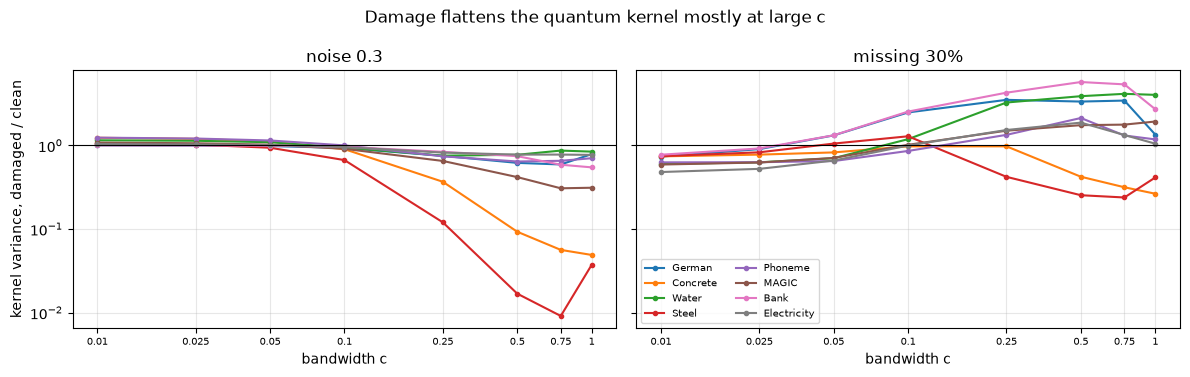

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, kind in zip(axes, ["noise", "missing"]):
    for name in DATASETS:
        r = A.loc[(SHORT[name], STRONGEST[kind])]
        ax.plot(BANDWIDTHS, r.values, "o-", ms=3, label=SHORT[name])
    ax.axhline(1, color="k", lw=0.8); ax.set_xscale("log"); ax.set_yscale("log"); ax.minorticks_off()
    ax.set_xticks(BANDWIDTHS); ax.set_xticklabels([f"{c:g}" for c in BANDWIDTHS], fontsize=7)
    ax.set_title(f"{STRONGEST[kind]}"); ax.set_xlabel("bandwidth c"); ax.grid(alpha=0.3)
axes[0].set_ylabel("kernel variance, damaged / clean"); axes[1].legend(fontsize=7, ncol=2)
fig.suptitle("Damage flattens the quantum kernel mostly at large c"); plt.tight_layout()
plt.savefig(OUT / "fig_concentration.png", dpi=150); plt.show()

## **4.2**

In [18]:
rows = []
for (name, kind), g in D.groupby(["dataset", "kind"]):
    pts = g.groupby(["c", "level"]).agg(lv=("ratio", lambda r: np.log(gmean(r))), da=("dauc", "mean"))
    rho, p = spearmanr(pts.lv, pts.da)
    rows.append({"dataset": SHORT[name], "damage": kind, "Spearman rho": round(rho, 2), "p": round(p, 3),
                 "reading": "flattening goes with AUC loss" if (p < 0.05 and rho > 0) else
                            ("opposite direction" if p < 0.05 else "no clear link")})
E2B = pd.DataFrame(rows).pivot(index="dataset", columns="damage", values=["Spearman rho", "reading"]).loc[[SHORT[n] for n in DATASETS]]
E2B.to_csv(OUT / "e2_flattening_vs_auc.csv")
E2B

Spearman rho                              reading                               
damage           missing noise                        missing                          noise
dataset                                                                                     
German             -0.34   0.2                  no clear link                  no clear link
Concrete            0.68   0.8  flattening goes with AUC loss  flattening goes with AUC loss
Water              -0.46  0.28             opposite direction                  no clear link
Steel               0.15  0.38                  no clear link                  no clear link
Phoneme            -0.66  0.24             opposite direction                  no clear link
MAGIC              -0.76  0.65             opposite direction  flattening goes with AUC loss
Bank               -0.62  0.33             opposite direction                  no clear link
Electricity        -0.46  0.31             opposite direction                  no clear link

## **4.3**

In [19]:
tuned = F[F.model == Q][["dataset", "setting", "seed", "fold", "c"]]
rows = {}
for name in DATASETS:
    r = {}
    for kind in ["missing", "noise"]:
        s = STRONGEST[kind]
        m = tuned[(tuned.dataset == name) & (tuned.setting == s)].merge(D[(D.dataset == name) & (D.setting == s)],
                                                                         on=["dataset", "setting", "seed", "fold", "c"])
        r[(s, "ratio at chosen c")] = round(gmean(m.ratio), 2)
        r[(s, "ratio at c = 1")] = float(f"{gmean(D[(D.dataset == name) & (D.setting == s) & (D.c == 1.0)].ratio):.2g}")
    rows[SHORT[name]] = r
E2C = pd.DataFrame(rows).T
E2C.columns = pd.MultiIndex.from_tuples(E2C.columns)
E2C

missing 30%                        noise 0.3               
            ratio at chosen c ratio at c = 1 ratio at chosen c ratio at c = 1
German                   0.86           1.30              1.00          0.790
Concrete                 0.85           0.26              1.10          0.049
Water                    2.80           4.00              0.83          0.840
Steel                    0.76           0.41              0.67          0.037
Phoneme                  0.76           1.20              1.00          0.700
MAGIC                    0.90           1.90              0.98          0.310
Bank                     2.11           2.70              0.68          0.550
Electricity              0.61           1.10              1.01          0.770

### 4.4 Matched zoom: quantum vs RBF

For every fold and bandwidth c, an RBF kernel gets the gamma at which its clean similarities have the same mean as the quantum kernel's; both are then damaged with exactly the same seeds. This recomputes RBF kernels only (a few minutes).

In [20]:
def match_gamma(D2, target):
    off = D2[~np.eye(len(D2), dtype=bool)]
    lo, hi = -12.0, 8.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if np.exp(-np.exp(mid) * off).mean() > target else (lo, mid)
    return float(np.exp((lo + hi) / 2))


start, rows = time.perf_counter(), []
for name in DATASETS:
    X, y, _, _ = load_ready(name); y = y.astype(int); cols = noise_columns(name)
    ck = clean_k.loc[name]
    dn = D[D.dataset == name].set_index(["kind", "level", "c", "seed", "fold"]).ratio
    for seed in SEEDS:
        for fold, (learn, _) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y)):
            D2 = euclidean_distances(X[learn], squared=True)
            gam = {c: match_gamma(D2, ck.loc[(c, seed, fold), "kernel_mean"]) for c in BANDWIDTHS}
            v_clean = {c: off_diagonal_stats(np.exp(-gam[c] * D2))[1] for c in BANDWIDTHS}
            for kind in ["missing", "noise"]:
                for level in LEVELS[kind]:
                    Xd, _ = corrupt_training(X[learn], y[learn], kind, level, corruption_seed(name, kind, seed, fold), cols)
                    D2d = euclidean_distances(Xd, squared=True)
                    for c in BANDWIDTHS:
                        rows.append({"dataset": name, "damage": kind, "c": c, "q": dn.loc[(kind, round(level, 4), c, seed, fold)],
                                     "rbf": off_diagonal_stats(np.exp(-gam[c] * D2d))[1] / v_clean[c]})
    print(f"  {SHORT[name]:12s} done ({time.perf_counter() - start:.0f} s)")

E = pd.DataFrame(rows)
E["zone"] = np.where(E.c >= 0.25, "large c (≥ 0.25)", "small c (< 0.25)")
E2E = E.groupby(["dataset", "damage", "zone"]).apply(lambda g: gmean(g.q) / gmean(g.rbf)).unstack("zone")
E2E.index = E2E.index.set_levels(E2E.index.levels[0].map(SHORT), level=0)
E2E.to_csv(OUT / "e2_matched_zoom.csv")
large = E2E["large c (≥ 0.25)"]
print(f"Large c: quantum flattens more in {(large < 0.8).sum()}/{len(large)}, RBF more in {(large > 1.25).sum()}/{len(large)}, "
      f"similar in {((large >= 0.8) & (large <= 1.25)).sum()}/{len(large)}")
E2E.style.format("{:.2f}")

  German       done (10 s)
  Concrete     done (14 s)
  Water        done (24 s)
  Steel        done (36 s)
  Phoneme      done (49 s)
  MAGIC        done (61 s)
  Bank         done (74 s)
  Electricity  done (86 s)
Large c: quantum flattens more in 4/16, RBF more in 2/16, similar in 10/16


## 5 · The small-c puzzle

At small c the kernel is almost all ones and nearly singular, yet it often gives the best AUC. Two checks on clean data, same 25 folds:

- **Shuffled labels.** Train with the labels scrambled. AUC must fall to about 0.5 at every c; if small c still scored well, it would be an artefact.
- **CKA similarity** to three classical kernels (linear, quadratic, and SVM-RBF at the gamma it chose). CKA = 1 means the same geometry: which classical kernel does the quantum kernel resemble?

This trains the quantum SVM again with shuffled labels (about 5–15 minutes).

In [21]:
def centred(Km):
    n = len(Km); H = np.eye(n) - 1 / n
    return H @ Km @ H


def cka(a, b):
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


def svm_auc(Kl, yl, Kc, yc, seed):
    inner = list(StratifiedKFold(3, shuffle=True, random_state=seed).split(np.zeros(len(yl)), yl))
    best = max(C_GRID, key=lambda C: np.mean([roc_auc_score(yl[b], SVC(kernel="precomputed", C=C, class_weight="balanced")
                                                            .fit(Kl[np.ix_(a, a)], yl[a]).decision_function(Kl[np.ix_(b, a)]))
                                              for a, b in inner]))
    return roc_auc_score(yc, SVC(kernel="precomputed", C=best, class_weight="balanced").fit(Kl, yl).decision_function(Kc))


rbf_gamma = (F[(F.model == RBF) & (F.kind == "clean")].set_index(["dataset", "seed", "fold"]).params
             .map(lambda s: float(re.search(r"'gamma':\s*(?:np\.float64\()?([0-9.eE+-]+)", s).group(1))))
start, rows = time.perf_counter(), []
for name in DATASETS:
    X, y, _, _ = load_ready(name); y = y.astype(int)
    Kq = {c: kernel_from_states(*(2 * [get_states(X, X.shape[1], c=c)])) for c in BANDWIDTHS}
    acc = {c: {"shuffled": [], "linear": [], "quadratic": [], "RBF": []} for c in BANDWIDTHS}
    for seed in SEEDS:
        for fold, (learn, check) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y)):
            Xl = X[learn]
            y_shuffled = np.random.default_rng(1000 * seed + fold).permutation(y[learn])
            ref = {"linear": centred(Xl @ Xl.T), "quadratic": centred((Xl @ Xl.T + 1) ** 2),
                   "RBF": centred(np.exp(-rbf_gamma.loc[(name, seed, fold)] * euclidean_distances(Xl, squared=True)))}
            for c in BANDWIDTHS:
                Kl = Kq[c][np.ix_(learn, learn)]
                acc[c]["shuffled"].append(svm_auc(Kl, y_shuffled, Kq[c][np.ix_(check, learn)], y[check], seed))
                for k, R in ref.items():
                    acc[c][k].append(cka(centred(Kl), R))
    true_auc = FIXED[(FIXED.dataset == name) & (FIXED.kind == "clean")].groupby("c").auc.mean()
    rows += [{"dataset": SHORT[name], "c": c, "AUC true labels": true_auc[c], "AUC shuffled labels": np.mean(a["shuffled"]),
              **{f"CKA {k}": np.mean(a[k]) for k in ["linear", "quadratic", "RBF"]}} for c, a in acc.items()]
    print(f"  {SHORT[name]:12s} done ({time.perf_counter() - start:.0f} s)")

E3 = pd.DataFrame(rows)
E3.to_csv(OUT / "e3_by_c.csv", index=False)
print(f"\nShuffled-label AUC over all {len(E3)} dataset × c cells: mean {E3['AUC shuffled labels'].mean():.3f}, "
      f"range {E3['AUC shuffled labels'].min():.3f}–{E3['AUC shuffled labels'].max():.3f} (chance = 0.5)")

  German       done (70 s)
  Concrete     done (116 s)
  Water        done (168 s)
  Steel        done (284 s)
  Phoneme      done (322 s)
  MAGIC        done (356 s)
  Bank         done (459 s)
  Electricity  done (493 s)

Shuffled-label AUC over all 64 dataset × c cells: mean 0.508, range 0.453–0.581 (chance = 0.5)


In [22]:
summary = []
for name, g in E3.groupby("dataset", sort=False):
    b = g.loc[g["AUC true labels"].idxmax()]
    cka_best = {k: b[f"CKA {k}"] for k in ["linear", "quadratic", "RBF"]}
    summary.append({"dataset": name, "best c": b.c, "AUC (true)": round(b["AUC true labels"], 3),
                    "AUC (shuffled) at best c": round(b["AUC shuffled labels"], 3),
                    "CKA at c ≤ 0.05 (linear)": f"{g[g.c <= 0.05]['CKA linear'].min():.2f}–{g[g.c <= 0.05]['CKA linear'].max():.2f}",
                    **{f"CKA {k} at best c": round(v, 2) for k, v in cka_best.items()},
                    "most similar at best c": max(cka_best, key=cka_best.get)})
E3S = pd.DataFrame(summary).set_index("dataset")
E3S.to_csv(OUT / "e3_summary.csv")
E3S

,best c,AUC (true),AUC (shuffled) at best c,CKA at c ≤ 0.05 (linear),CKA linear at best c,CKA quadratic at best c,CKA RBF at best c,most similar at best c
dataset,,,,,,,,
German,0.01,0.733,0.474,0.76–0.83,0.83,0.81,0.79,linear
Concrete,0.05,0.927,0.548,0.81–0.81,0.81,0.80,0.83,RBF
Water,0.25,0.563,0.523,0.81–0.82,0.30,0.30,0.78,RBF
Steel,0.10,0.761,0.490,0.87–0.93,0.58,0.59,0.84,RBF
Phoneme,0.10,0.851,0.475,0.83–0.85,0.83,0.84,0.77,quadratic
MAGIC,0.10,0.850,0.497,0.89–0.91,0.74,0.72,0.85,RBF
Bank,1.00,0.730,0.581,0.82–0.88,0.20,0.23,0.54,RBF
Electricity,0.05,0.795,0.491,0.82–0.83,0.82,0.83,0.84,RBF


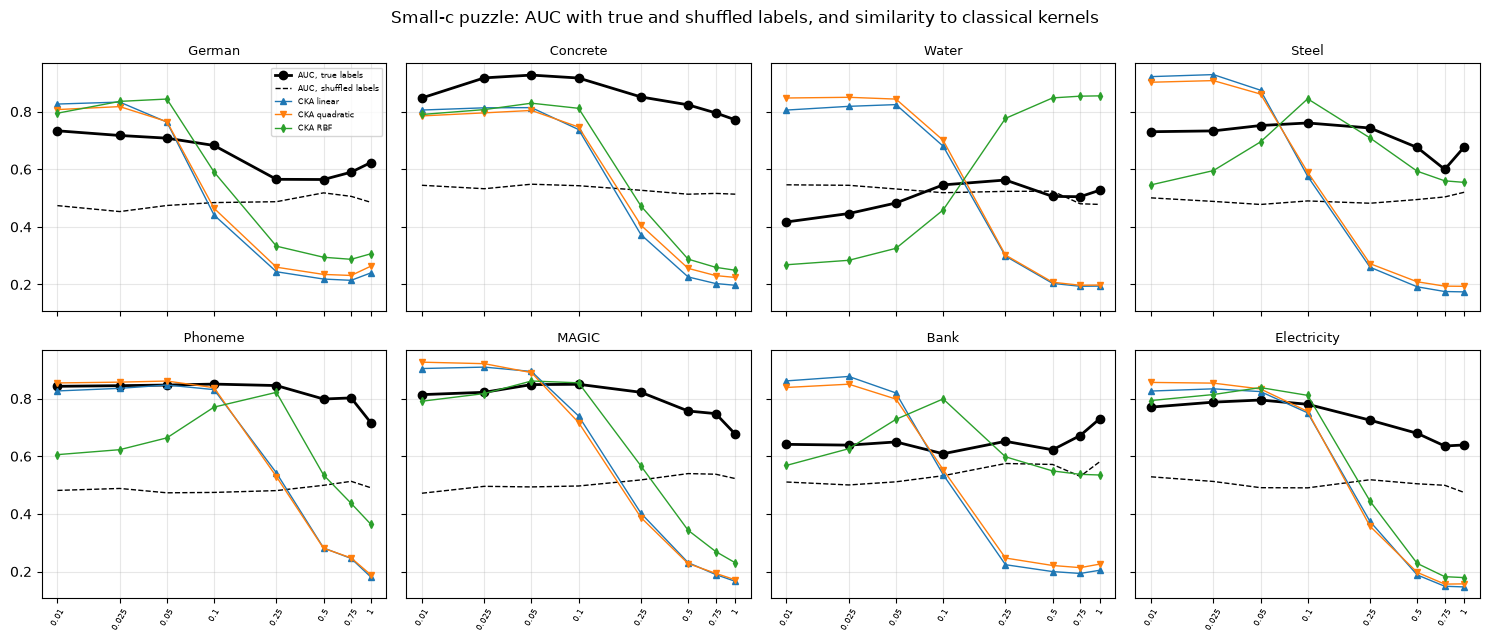

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True, sharey=True)
for ax, (name, g) in zip(axes.ravel(), E3.groupby("dataset", sort=False)):
    ax.plot(g.c, g["AUC true labels"], "ko-", lw=2, label="AUC, true labels")
    ax.plot(g.c, g["AUC shuffled labels"], "k--", lw=1, label="AUC, shuffled labels")
    for col, st in [("CKA linear", "^-"), ("CKA quadratic", "v-"), ("CKA RBF", "d-")]:
        ax.plot(g.c, g[col], st, ms=4, lw=1, label=col)
    ax.set_xscale("log"); ax.minorticks_off(); ax.set_title(name, fontsize=9); ax.grid(alpha=0.3)
    ax.set_xticks(BANDWIDTHS); ax.set_xticklabels([f"{c:g}" for c in BANDWIDTHS], rotation=60, fontsize=6)
axes[0, 0].legend(fontsize=6)
fig.suptitle("Small-c puzzle: AUC with true and shuffled labels, and similarity to classical kernels")
plt.tight_layout(); plt.savefig(OUT / "fig_small_c.png", dpi=150); plt.show()